In [53]:
import matplotlib.pyplot as plt
import torch
def init_inputs(r_min = -2.0, r_max = 2.0):
    inputs = torch.arange(r_min, r_max + 0.1, 0.1)
    return inputs

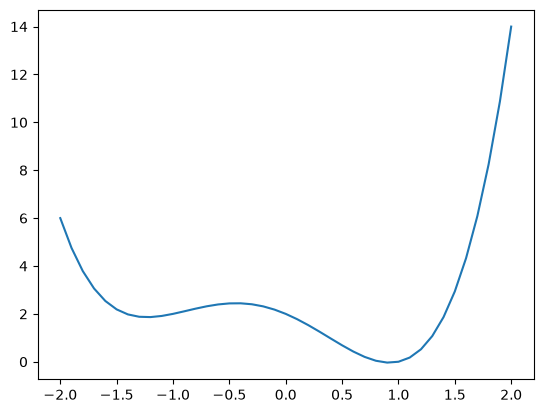

In [54]:
def objective(x):
    return x ** 4 + x ** 3 - 2 * x ** 2 - 2 * x + 2

inputs = init_inputs()
results = objective(inputs)
plt.plot(inputs, results)
plt.show()

In [55]:
def derivative(x):
    return 4 * x ** 3 + 3 * x ** 2 - 4 * x - 2

In [56]:
num_epochs = 20
learning_rate = 0.05
def nest_momentum(input, num_epochs, learning_rate, momentum):
    solutions, scores = [], []
    solution = input
    change = 0.0
    solution_eval = objective(solution)
    solutions.append(solution)
    scores.append(solution_eval)

    for epoch in range(num_epochs):
        # projected solution
        projected = solution + momentum * change
        gradient = derivative(projected)

        new_change = momentum * change - learning_rate * gradient

        solution = solution + new_change
        change = new_change
        solution_eval = objective(solution)

        solutions.append(solution)
        scores.append(solution_eval)

        print(f'Epoch: %0.2d --f(%0.3f) = %.5f' % (epoch, solution, solution_eval))
    return solutions, scores
solutions, scores = nest_momentum(input, num_epochs, learning_rate, 0.7)

Epoch: 00 --f(-1.300) = 1.87910
Epoch: 01 --f(-0.864) = 2.14715
Epoch: 02 --f(-0.583) = 2.40373
Epoch: 03 --f(-0.374) = 2.43544
Epoch: 04 --f(-0.178) = 2.28853
Epoch: 05 --f(0.050) = 1.89573
Epoch: 06 --f(0.343) = 1.13313
Epoch: 07 --f(0.680) = 0.24393
Epoch: 08 --f(0.919) = -0.03770
Epoch: 09 --f(0.970) = -0.02364
Epoch: 10 --f(0.952) = -0.03251
Epoch: 11 --f(0.929) = -0.03749
Epoch: 12 --f(0.918) = -0.03766
Epoch: 13 --f(0.917) = -0.03761
Epoch: 14 --f(0.920) = -0.03772
Epoch: 15 --f(0.922) = -0.03775
Epoch: 16 --f(0.923) = -0.03775
Epoch: 17 --f(0.923) = -0.03775
Epoch: 18 --f(0.922) = -0.03775
Epoch: 19 --f(0.922) = -0.03775


[]

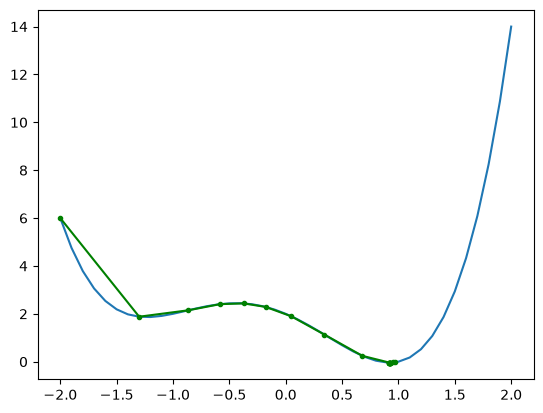

In [57]:
results = objective(inputs)
plt.plot(inputs, results)
plt.plot(solutions, scores, '.-', color = 'green')
plt.plot()